# Learning a shared space for morphology and expression

**The question:** can a cell's appearance and its spatial gene calls independently place it in a compatible biological space?

This notebook walks through a completed CPU comparison of **regularized CCA, PLS, MOFA2 with separate ridge projections, and a small paired neural model**. It builds on the earlier tutorials but now learns the correspondence between modalities. The models live in reusable scripts, so the explanations and plots stay short.

Start by running top to bottom. **The default opens saved results and does not retrain.** When ready, change `RUN_NEW` below to run a fresh experiment.

**Prerequisites:** select `/g/kreshuk/frazer/envs/morpho_shared_space/bin/python` as the kernel/interpreter; retain the local input tables and embeddings in the site config. The new environment adds MOFA2 while inheriting the existing MorphoFeats_dev stack. CPU only, two threads. The pilot samples 4,000 of the 11,377 matched nonempty cells. See [the method guide](docs/shared_space_analysis.md) for precise settings, formulas, environment details and output conventions.

The binary values are **thresholded spatial calls**. A zero does not establish biological gene silencing. The separate scRNA reference's inherited UMAP is not an input to these models; only its small gene-name dictionary is read.

## 1. What is learned, and what is only a picture?

For training cells we have both descriptions, linked by the explicit cell↔nucleus mapping:

**Morphology → learned morphology projection → shared coordinates**  
**Expression → learned expression projection → shared coordinates**

We then hold out cells. Each held-out cell is projected **once from morphology alone and once from expression alone**. Agreement between those projections is the test. No expression enters its morphology projection.

A PCA or UMAP plot is a later display of the shared coordinates. The scores below are calculated in the learned space, not in the two plotting dimensions. The two modalities need not agree perfectly: each can contain useful information absent from the other.

In [ ]:
from pathlib import Path
import sys, json
REPO = Path('/g/kreshuk/frazer/projects/MorphoFeatures')
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

CONFIG_PATH = REPO / 'configs/sites/shared_space_platynereis.yaml'
RUN_NEW = True
SAVED_RUN = REPO / 'outputs/exploration/shared_space/20261011-160119-122482'

# These choices change which saved result is displayed; they do not retrain anything.
MORPHOLOGY = 'MorphoFeatures'  # Also try 'DINO'.
SCHEME = 'spatial'  # Also try 'random_pair_grouped'.
METHOD = 'rcca'  # 'pls', 'mofa2_ridge', 'paired_neural'
FACTOR = 1
GENE = 'Mef2c'  # Example chosen for interpretation, not by its test score.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from morphofeatures.analysis.shared_space.experiment import read_config, run, project_saved

config = read_config(CONFIG_PATH)
if RUN_NEW:
    # Example exploration: config['analysis']['factors'] = 20
    # More cells: config['analysis']['max_cells'] = None
    # No neural model: config['analysis']['methods'] = ['rcca', 'pls', 'mofa2_ridge', 'rcca_shuffled']
    RUN = run(config)
else:
    RUN = SAVED_RUN
if not (RUN / 'provenance.json').exists():
    raise FileNotFoundError('Saved run missing. Set RUN_NEW=True to create results from the configured inputs.')
manifest = json.loads((RUN / 'provenance.json').read_text())
if manifest['status'] != 'complete':
    raise RuntimeError('This run is incomplete; inspect its logs before interpreting results.')
scores = pd.read_csv(RUN / 'tables/scores.tsv', sep='\t')
splits = pd.read_csv(RUN / 'tables/splits.tsv', sep='\t')
genes = pd.read_csv(RUN / 'tables/genes.tsv', sep='\t')
print('Reading:', RUN)
print('Selected / eligible cells:', manifest['selected_cells'], '/', manifest['eligible_cells'])
print('Actual settings:', {k: manifest['config']['analysis'][k] for k in
    ['seed', 'factors', 'morphology_pcs', 'cca_ridge', 'mofa_iterations', 'neural_epochs']})
display(splits.groupby(['scheme', 'role']).size().rename('cells').to_frame())

Reading: /g/kreshuk/frazer/projects/MorphoFeatures/outputs/exploration/shared_space/20261011-160119-122482
Selected / eligible cells: 4000 / 11377
Actual settings: {'seed': 42, 'factors': 10, 'morphology_pcs': 40, 'cca_ridge': 0.1, 'mofa_iterations': 300, 'neural_epochs': 60}


cells
scheme              role         
random_pair_grouped test      998
                    train    3002
spatial             purged      1
                    test     1041
                    train    2958

## 2. Make the comparisons fair

All methods use the **same cells, genes and holdout partition** within each scheme. Every feature mask, normalization, PCA, shared model and decoder is learned on the training cells.

- **Random holdout:** keeps known bilateral partners together. This asks about interpolation within this animal.
- **Spatial holdout:** holds out whole coordinate-derived regions and removes any training partners of test cells. This asks about transfer to other regions. There is no physical buffer around region boundaries.

The split is fixed, rather than a tuned or repeated cross-validation experiment. It is a first comparison, not a final claim about generalization to another animal. RNA-reference batch labels are not EM specimen replicates.

The original 480-feature MorphoFeatures vectors and the DINO vectors represent different input recipes. Comparing them is useful, but it is not a controlled test of image backbones on identical inputs.

In [2]:
audit = pd.read_csv(RUN / 'tables/cohort_audit.tsv', sep='\t')
display(audit.groupby('reason').size().rename('cells').to_frame())
print('Selected genes:', len(genes))
print('Training-constant genes are excluded from alignment, but remain in prediction exports.')
print('Train/test/purged identities are in tables/splits.tsv; both cell_id and nucleus_id are preserved.')

Selected genes: 201
Training-constant genes are excluded from alignment, but remain in prediction exports.
Train/test/purged identities are in tables/splits.tsv; both cell_id and nucleus_id are preserved.


,cells
reason,
all_zero_expression,5
eligible_outside_random_cpu_sample,7377
selected,4000


## 3. Four ways of learning the correspondence

| Method | Plain-language idea | What to watch |
|---|---|---|
| Regularized CCA | Find morphology and gene combinations that correlate across paired cells. | Regularization stops unstable directions from dominating. |
| PLS | Find combinations that change together, emphasizing covariance. | Different gene prevalence and variance affect its priorities. |
| MOFA2 + ridge projections | Explain both measurements with a small set of hidden factors, then learn how each modality predicts those factors. | Some factors may mainly describe one modality; the separate projections are approximate. |
| Paired neural pilot | Train two small networks to bring paired cells together, while reconstructing their inputs. | Good retrieval need not imply good gene prediction; similar cells can be misleading contrastive negatives. |

**MOFA2 detail that matters:** its native model is fitted with continuous/Gaussian morphology and binary/Bernoulli expression. It produces factors for training cells using both views. We then fit two ridge regressions on those training cells to predict the factors independently. These frozen regressions give coordinates for new cells. This is labeled **MOFA2 + ridge projections**, not presented as native MOFA posterior inference.

<details><summary>Optional mathematical and preprocessing details</summary>

Morphology is training-centered, row-L2-normalized and reduced to up to 40 PCs. Retained PC scores are scaled to unit training variance. Expression is left binary; training-constant genes are removed. Scaling PCs gives smaller retained components more influence than in the earlier unwhitened baseline.

Ridge CCA adds $\lambda\,\mathrm{tr}(C)/d$ to each covariance diagonal before whitening the cross-covariance; $\lambda=0.1$. PLS uses `PLSCanonical(scale=False, algorithm='svd')`. Both retain ten factors and use training-only score scaling. These are different objectives; PLS is not being claimed to use the CCA covariance penalty.

MOFA uses Gaussian/Bernoulli likelihoods, ARD and sparse weights, up to 300 iterations, CPU only. Its two ridge heads use `alpha = 0.01 × n_train`. The neural pilot uses 64 hidden units, ten outputs, symmetric InfoNCE with temperature 0.2, plus morphology MSE and binary-expression reconstruction; 60 fixed epochs. No settings are selected using the reported test scores.

References: [PLS and CCA](https://scikit-learn.org/stable/modules/cross_decomposition.html), [MOFA2 likelihoods](https://biofam.github.io/MOFA2/faq.html). The [method guide](docs/shared_space_analysis.md) records the full recipe.
</details>

## 4. Two scores answer different questions

**Matching:** given a held-out morphology vector, can we find the same cell's expression vector among 800 candidates? `recall@10` is the fraction whose correct partner is in the first ten. Chance is 10/800 = **1.25%** for the default candidate population. Equivalent binary profiles make exact-cell retrieval ambiguous; tied candidates are handled fairly. Shuffled-pair CCA is a control that learned from deliberately incorrect training pairings.

**Gene prediction:** can the morphology-only coordinates predict each binary gene call? The same small logistic classifier is fitted for each representation. Average precision (AP) measures how well positive cells are ranked; it is not ordinary classification accuracy. Its baseline depends on gene prevalence. We also report log-loss improvement over training prevalence: **positive values mean more informative probabilities**.

The controls are essential: **direct morphology** tests whether compression into a shared space helped; **position-only** tests how much anatomical location predicts; **training prevalence** ignores morphology and position. These models use only training cells. AP macro averages use the same sufficiently represented genes within a holdout scheme; different schemes can have different supported genes.

In [3]:
view = scores.loc[(scores['scheme'] == SCHEME) & scores['morphology'].isin([MORPHOLOGY, 'control'])].copy()
view['retrieval_percent'] = 100 * view['morph_to_expr_recall_at_k']
columns = ['method', 'train_cells', 'test_cells', 'supported_test_genes', 'retrieval_percent',
           'macro_AP', 'mean_log_loss_gain_bits', 'mean_paired_correlation', 'within_region_shuffle_correlation']
display(view[columns].round(3))
print('Retrieval uses the same saved candidates for all shared models; blank values are not applicable to the controls.')
print('Within-region shuffled correlation is a descriptive anatomy control, not a permutation p-value.')

Retrieval uses the same saved candidates for all shared models; blank values are not applicable to the controls.
Within-region shuffled correlation is a descriptive anatomy control, not a permutation p-value.


,method,train_cells,test_cells,supported_test_genes,retrieval_percent,macro_AP,mean_log_loss_gain_bits,mean_paired_correlation,within_region_shuffle_correlation
14,training_prevalence,2958,1041,178,NaN,0.122,0.000,NaN,NaN
15,position_RBF,2958,1041,178,NaN,0.277,0.047,NaN,NaN
16,morphology_direct,2958,1041,178,NaN,0.322,0.067,NaN,NaN
17,rcca,2958,1041,178,13.438,0.326,0.072,0.466,0.108
18,pls,2958,1041,178,12.125,0.327,0.072,0.470,0.112
19,mofa2_ridge,2958,1041,178,12.500,0.315,0.071,0.434,0.119
20,paired_neural,2958,1041,178,13.500,0.304,0.063,0.449,0.141
21,rcca_shuffled,2958,1041,178,1.500,0.186,0.012,0.000,0.010


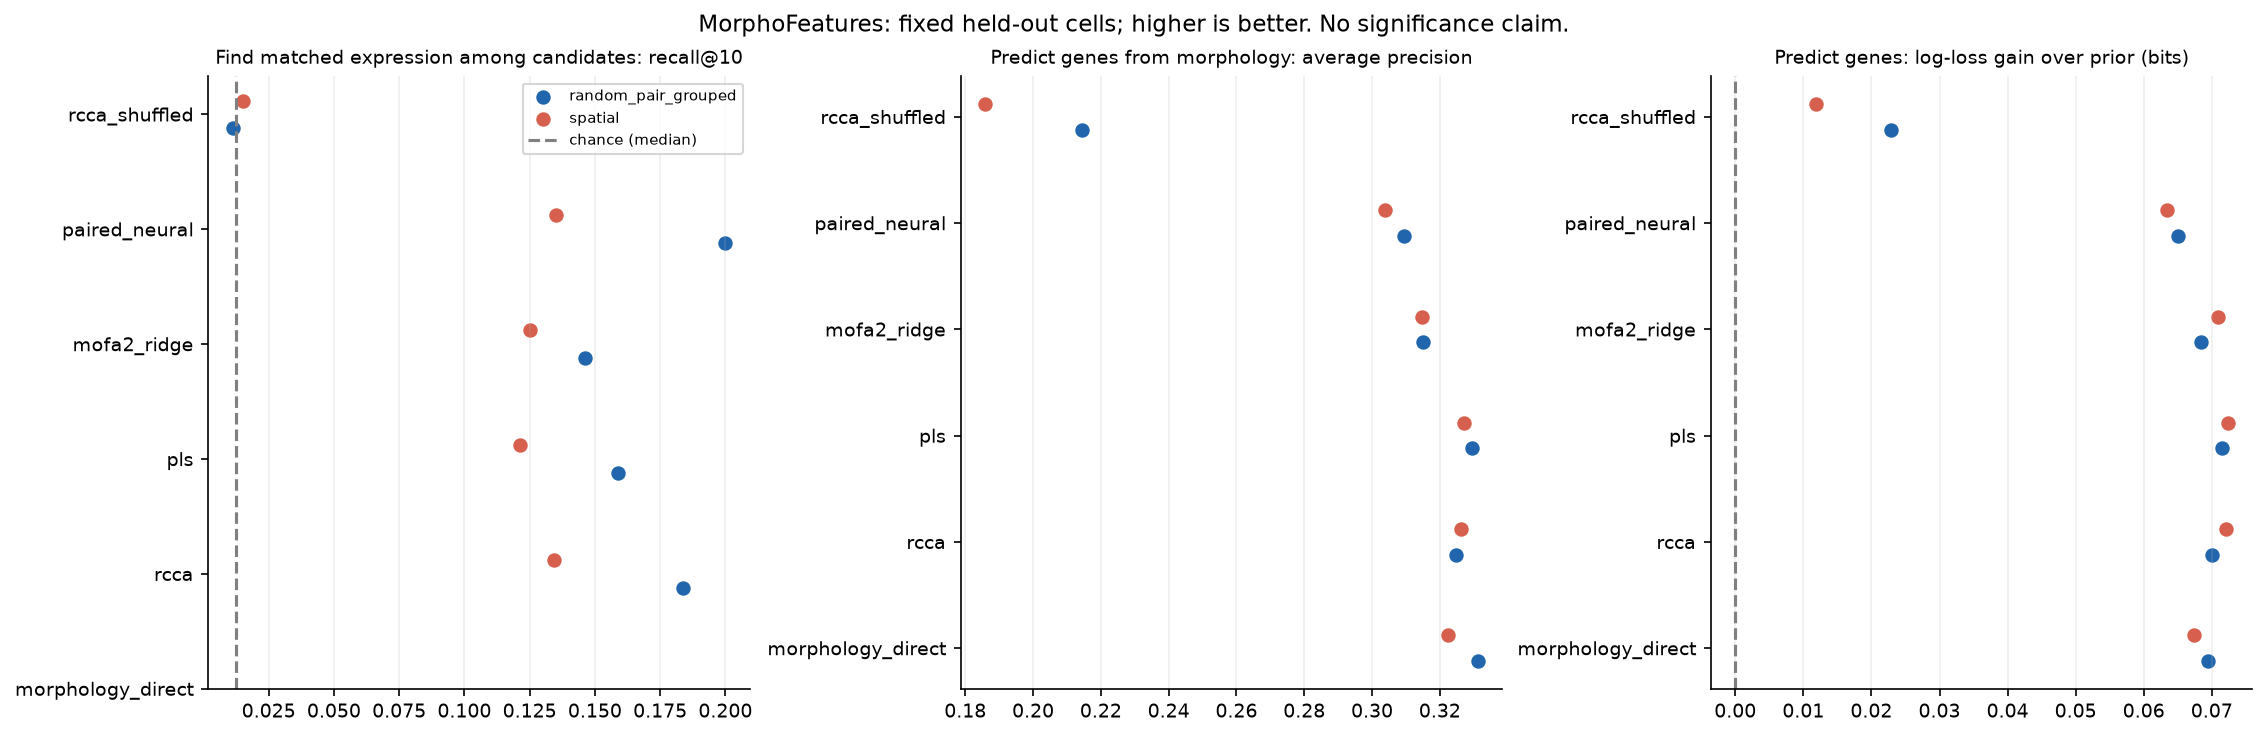

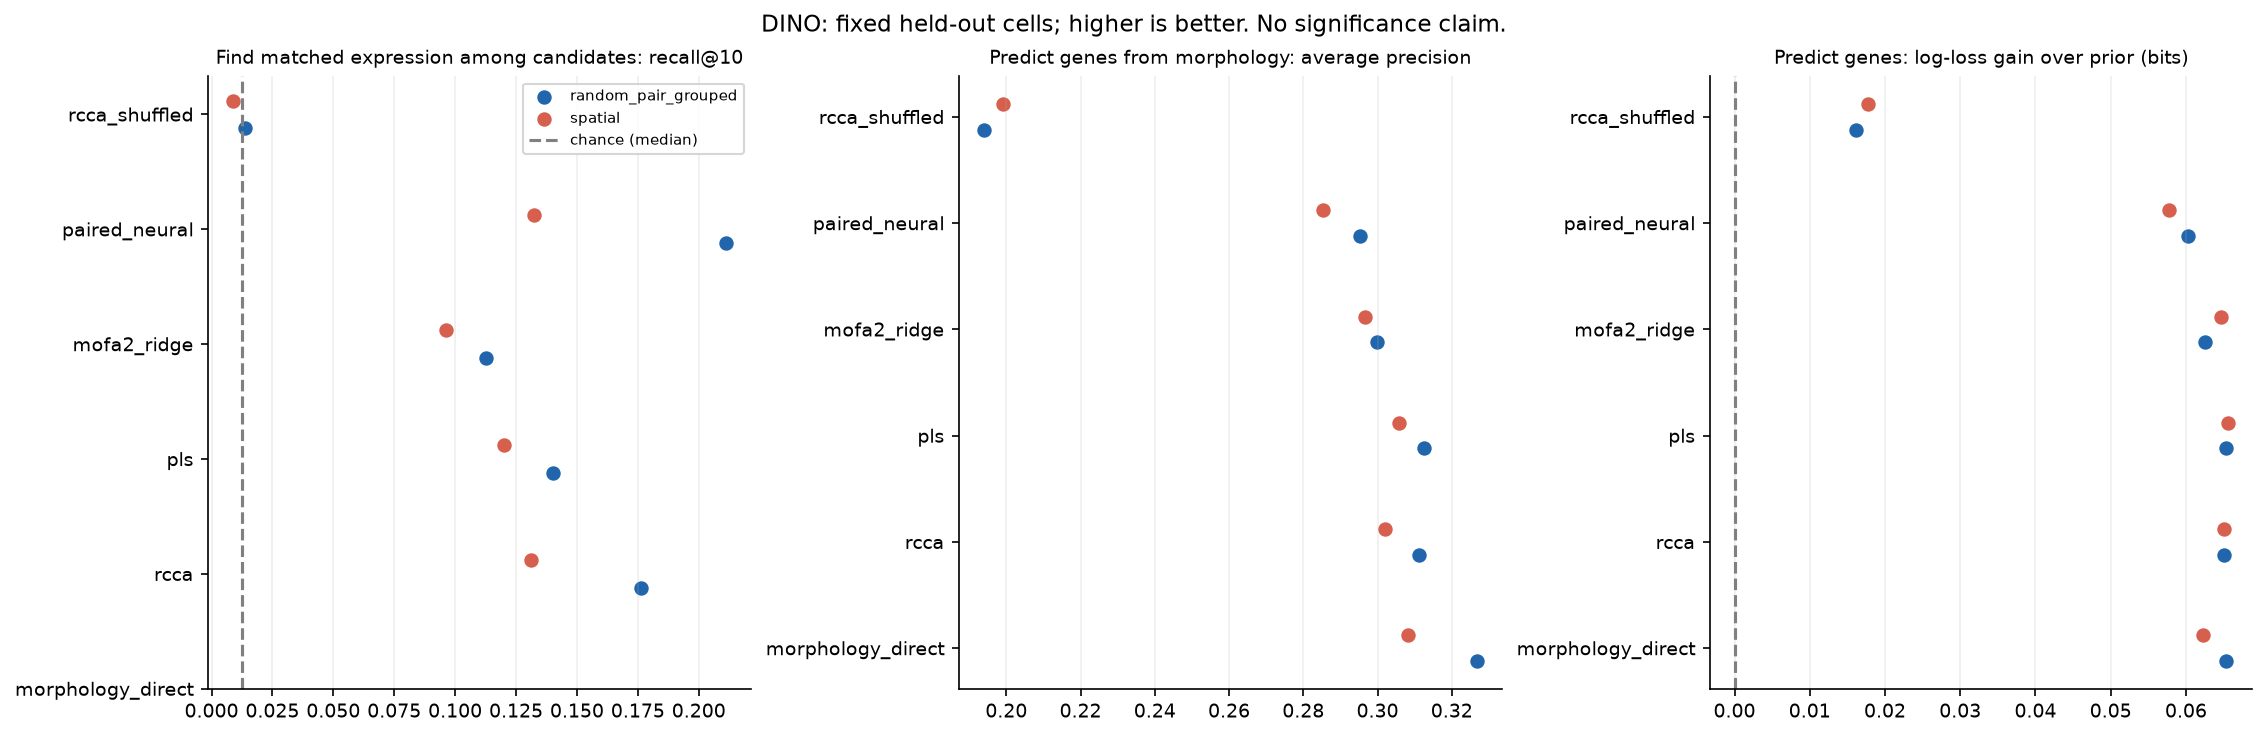

In [4]:
for name in manifest['config']['inputs']['morphology']:
    display(Image(filename=str(RUN / 'figures' / f'{name}_heldout_performance.png')))

## 5. Read the saved pilot without overclaiming

The following short interpretation is generated from the selected run. A model can be good at matching cells but lose information about individual genes. A higher score in one task is therefore not a universal winner.

The position-only baseline matters especially here because these are registered spatial calls. Good spatial-holdout performance is useful evidence, but neither this control nor region holdout removes every anatomical or registration confound.

In [5]:
for scheme in manifest['config']['analysis']['schemes']:
    selected = scores.loc[(scores['scheme'] == scheme) & (scores['morphology'] == MORPHOLOGY)]
    aligned = selected.loc[selected['method'].isin(['rcca', 'pls', 'mofa2_ridge', 'paired_neural'])]
    retrieval_best = aligned.loc[aligned['morph_to_expr_recall_at_k'].idxmax()]
    prediction_best = aligned.loc[aligned['macro_AP'].idxmax()]
    direct = selected.loc[selected['method'].eq('morphology_direct')].iloc[0]
    position = scores.loc[(scores['scheme'] == scheme) & scores['method'].eq('position_RBF')].iloc[0]
    print(f"{scheme}: highest observed retrieval is {retrieval_best['method']} "
          f"({100*retrieval_best['morph_to_expr_recall_at_k']:.1f}%; chance "
          f"{100*retrieval_best['chance_recall_at_k']:.2f}%).")
    print(f"  Highest shared-model AP: {prediction_best['method']}={prediction_best['macro_AP']:.3f}; "
          f"direct morphology={direct['macro_AP']:.3f}; position={position['macro_AP']:.3f}.")
print('These are descriptive point estimates from fixed settings, not significance tests or independently confirmed selections.')

random_pair_grouped: highest observed retrieval is paired_neural (20.0%; chance 1.25%).
  Highest shared-model AP: pls=0.330; direct morphology=0.331; position=0.356.
spatial: highest observed retrieval is paired_neural (13.5%; chance 1.25%).
  Highest shared-model AP: pls=0.327; direct morphology=0.322; position=0.277.
These are descriptive point estimates from fixed settings, not significance tests or independently confirmed selections.


## 6. Look at the same cells from each modality

Each row below is one learned model. The left panel uses morphology alone and the right uses expression alone. The colors show the same observed positive-call burden in both views, **only for inspection**.

The PCA display uses axes learned from training projections. The optional UMAP display is fitted once to the combined test points, then separated into panels with identical axes. No evaluation score uses this UMAP. Axes from different rows are unrelated; forcing separate UMAPs to look similar would not demonstrate alignment.

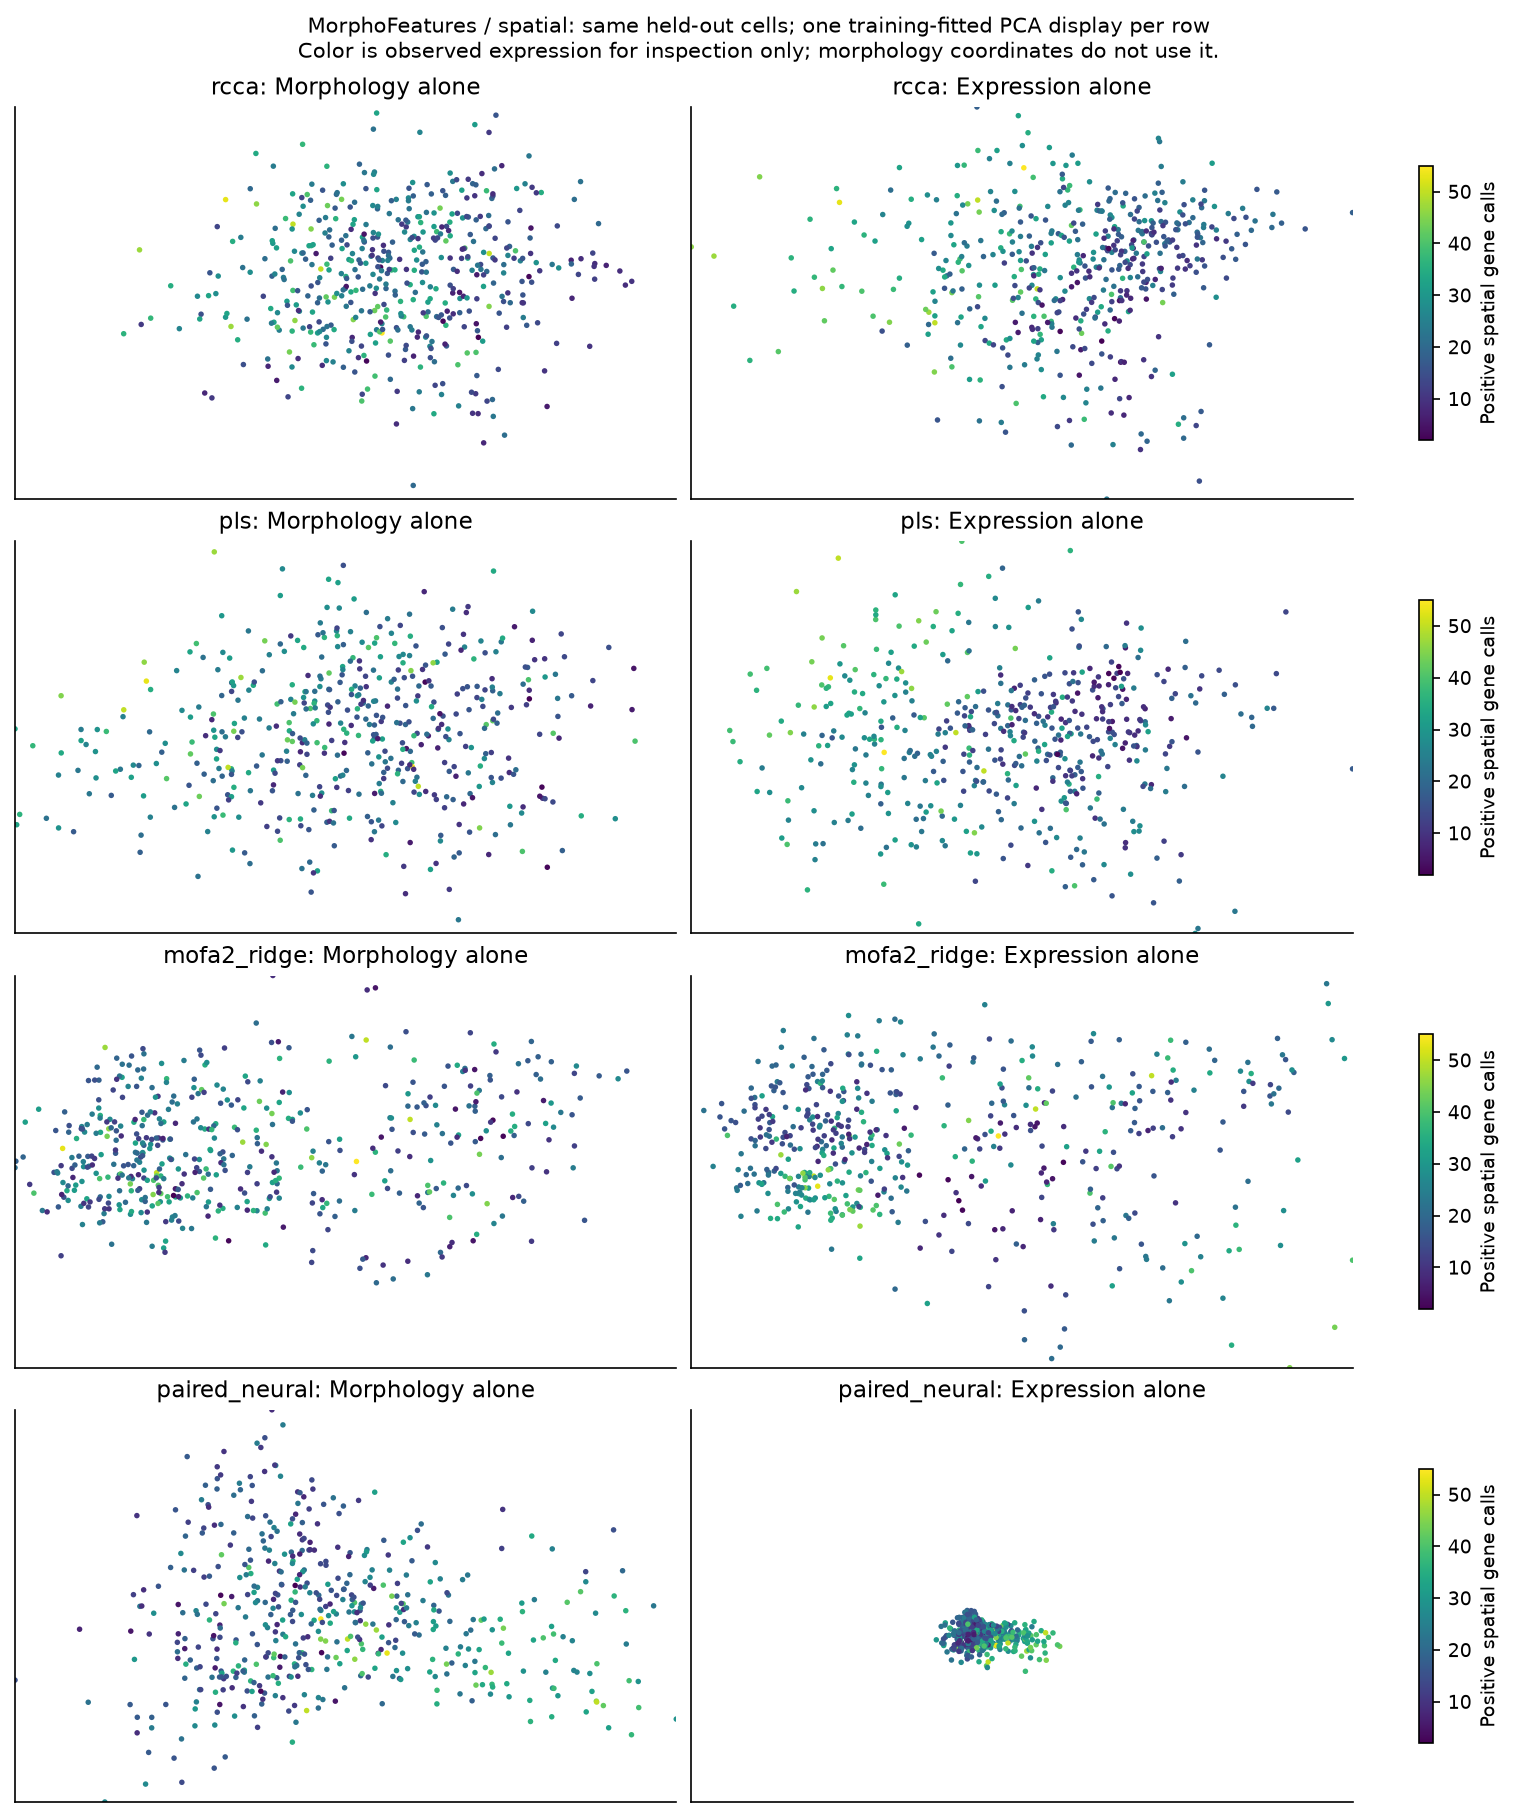

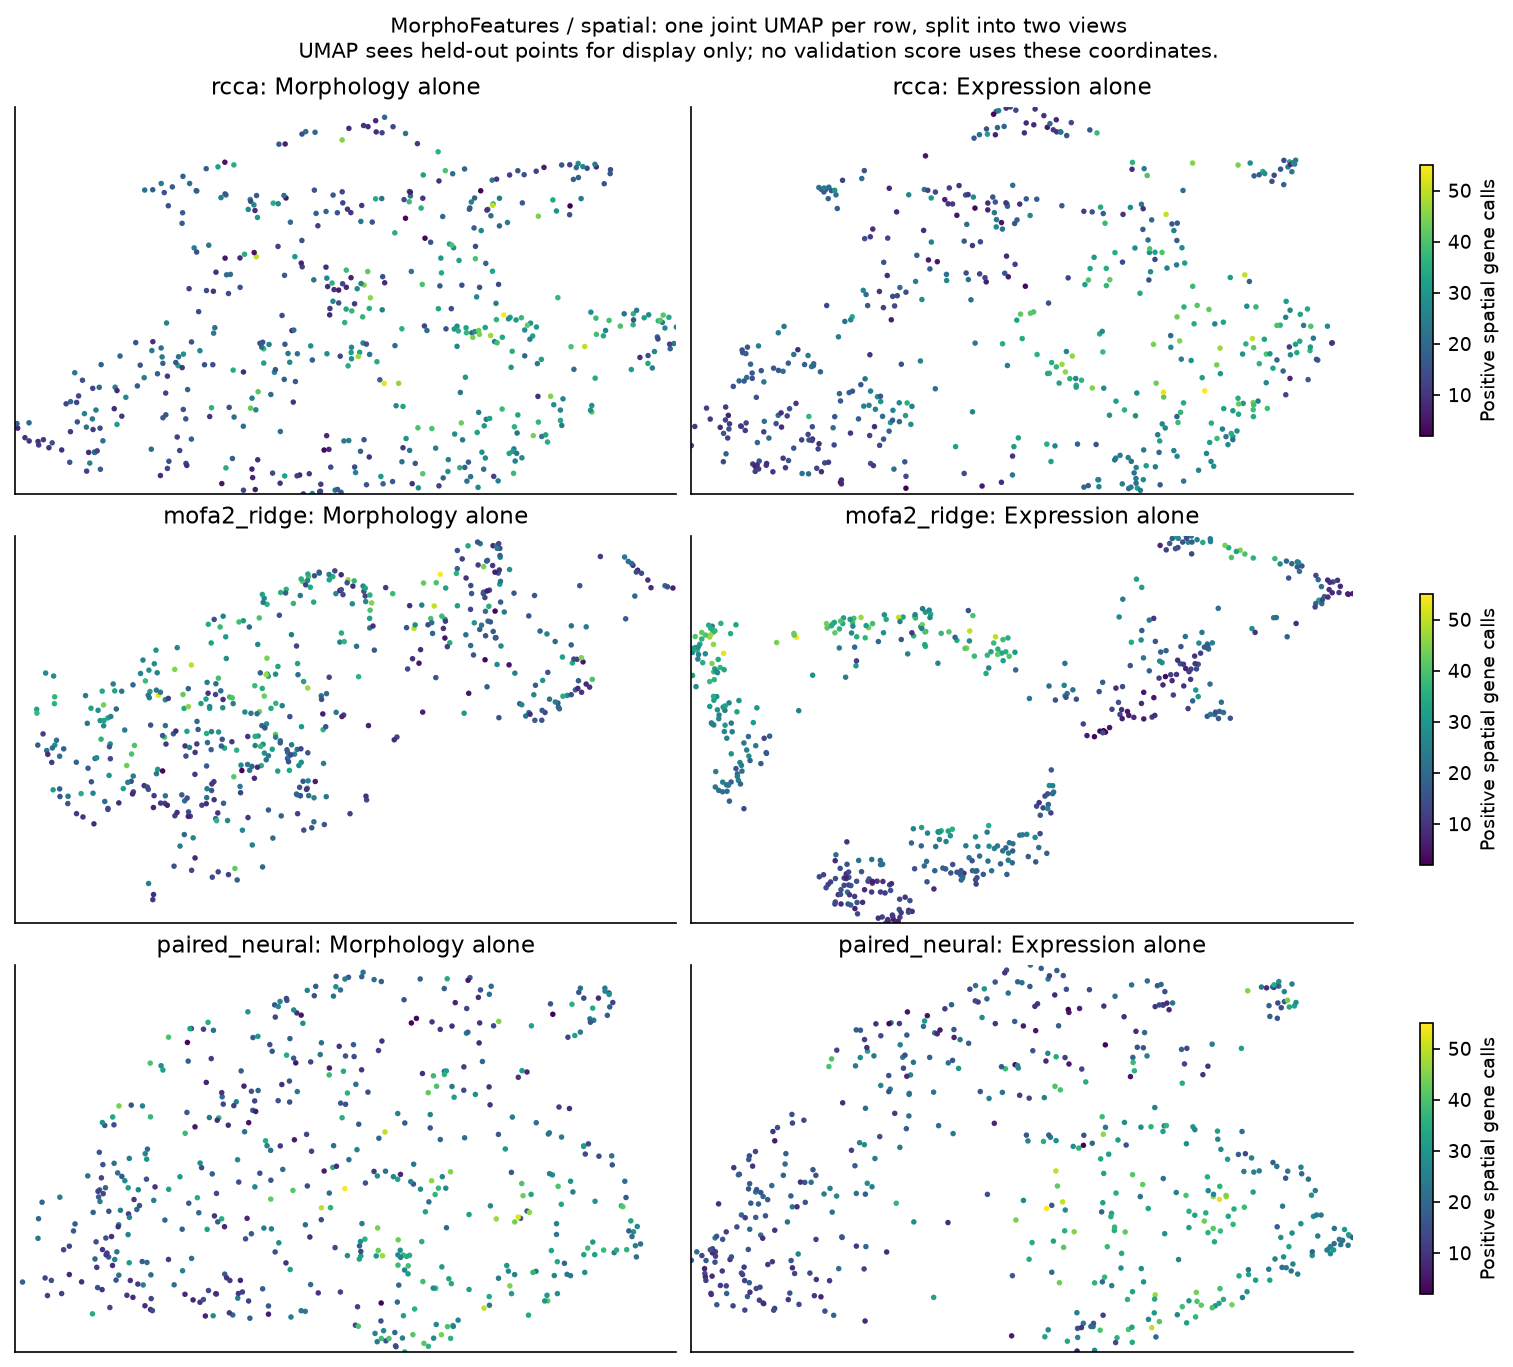

In [6]:
display(Image(filename=str(RUN / 'figures' / f'{MORPHOLOGY}_{SCHEME}_shared_pca.png')))
umap_path = RUN / 'figures' / f'{MORPHOLOGY}_{SCHEME}_shared_umap.png'
if umap_path.exists():
    display(Image(filename=str(umap_path)))

## 7. Check the MOFA fit and its projection approximation

MOFA can learn factors that are hard to predict from one view alone. The two training R² values below show how well the extra ridge projections reproduce the **joint training factors**. They diagnose the adapter; they are not held-out accuracy scores. Held-out matching and gene prediction above remain the relevant evaluation.

The ELBO curve tracks MOFA's fitting objective. A stable curve or convergence message indicates numerical stopping, not biological correctness. The 40 morphology PCs and roughly 200 binary genes also give the views different sizes; this pilot does not optimize view weighting.

,morphology,scheme,mofa_iterations_recorded,mofa_stopped_before_cap,mofa_morphology_head_train_R2,mofa_expression_head_train_R2
5,MorphoFeatures,random_pair_grouped,90.0,True,0.666,0.670
11,DINO,random_pair_grouped,115.0,True,0.728,0.607
19,MorphoFeatures,spatial,85.0,True,0.744,0.626
25,DINO,spatial,90.0,True,0.682,0.671


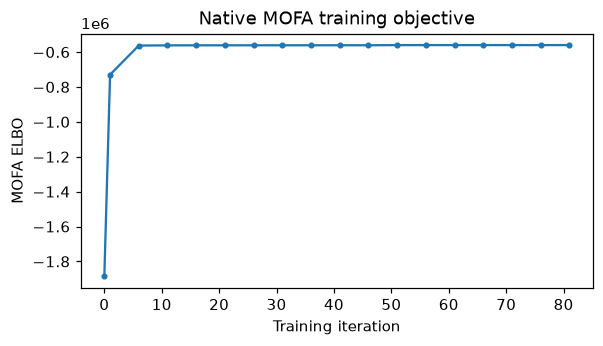

In [7]:
mofa_summary = scores.loc[scores['method'].eq('mofa2_ridge'), ['morphology', 'scheme',
    'mofa_iterations_recorded', 'mofa_stopped_before_cap',
    'mofa_morphology_head_train_R2', 'mofa_expression_head_train_R2']]
display(mofa_summary.round(3))
mofa_dir = RUN / 'models' / MORPHOLOGY / SCHEME / 'mofa2_ridge'
if mofa_dir.exists():
    trace = pd.read_csv(mofa_dir / 'mofa_training.tsv', sep='\t').dropna(subset=['elbo'])
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(trace['iteration'], trace['elbo'], marker='.')
    ax.set(xlabel='Training iteration', ylabel='MOFA ELBO', title='Native MOFA training objective')
    display(fig); plt.close(fig)

## 8. Which genes and cell characteristics follow a factor?

A factor is a learned direction, not automatically a biological process. We select five associated genes **using training cells**, then inspect their association with the morphology-only factor on held-out cells. This avoids selecting a gene merely because it looks impressive in the test data.

The next table compares the same factor with anatomical position, positive-call burden and simple measurements from the segmentation tables. These are **unadjusted descriptive correlations**. A positional association can motivate a within-region follow-up; it is not removed by merely reporting it.

**What the measurements mean:** voxel count is a size proxy, and bounding-box aspect ratio is an orientation-dependent shape proxy. Neither establishes physical volume without source resolution metadata. No surface or texture measurement is manufactured from a DINO coordinate. Texture interpretation needs inspection of the actual image patches and explicit texture measurements.

In [8]:
associations = pd.read_csv(RUN / 'tables/factor_gene_associations.tsv', sep='\t')
selected = associations.loc[(associations['morphology'] == MORPHOLOGY) & (associations['scheme'] == SCHEME)
    & (associations['method'] == METHOD) & (associations['factor'] == FACTOR)]
display(selected[['factor', 'gene', 'name', 'train_spearman', 'test_spearman']].round(3))
measurements = pd.read_csv(RUN / 'tables/factor_measurement_associations.tsv', sep='\t')
selected_measurements = measurements.loc[(measurements['morphology'] == MORPHOLOGY) & (measurements['scheme'] == SCHEME)
    & (measurements['method'] == METHOD) & (measurements['factor'] == FACTOR)]
display(selected_measurements[['descriptor', 'test_spearman']].round(3))

,factor,gene,name,train_spearman,test_spearman
500,1,XLOC-068990,kv33e,0.621,0.614
501,1,XLOC-011991,scn8aa,0.596,0.527
502,1,XLOC-004182,stathmin,0.567,0.581
503,1,XLOC-000875,syt,0.561,0.588
504,1,XLOC-026597,VAChT,0.539,0.555


,descriptor,test_spearman
800,cell_log1p_voxel_count,-0.608
810,cell_bbox_aspect_ratio,-0.154
820,nucleus_log1p_voxel_count,-0.113
830,nucleus_bbox_aspect_ratio,-0.223
840,positive_call_burden,0.328
850,anchor_x,0.500
860,anchor_y,0.148
870,anchor_z,-0.535


## 9. Inspect one gene and the corresponding cells

The example gene below is chosen explicitly in the first cell. The two groups are **below/above the spatial threshold**, not experimentally silenced/activated cells. Differences between them can be explained by cell type, location, measurement quality or other genes. These plots identify questions for follow-up; they do not estimate what a gene perturbation would do.

High and low factor cells are also listed with their actual IDs. Use `cell_id` for a cell segmentation and `nucleus_id` for a nucleus segmentation in the existing object viewer or [MoBIE workflow](docs/analysis_and_mobie.md). Those image/mesh inspections are the next step toward explaining what a learned vector means physically.

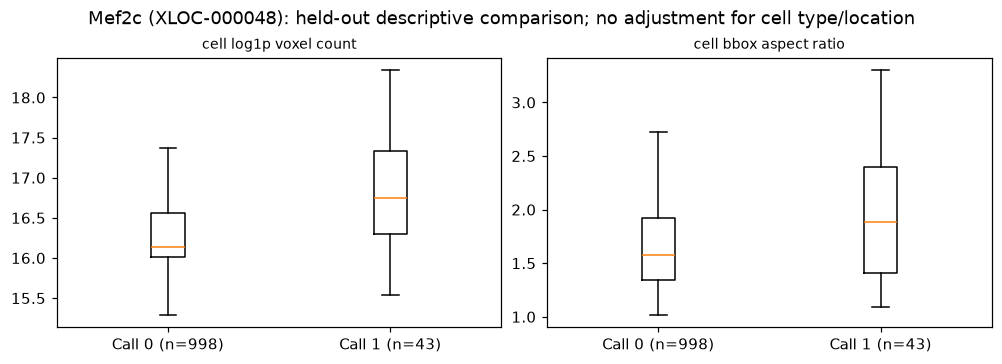

,extreme,cell_id,nucleus_id,factor_score,manual_label,spatial_region
600,low,7412,11460,-1.872986,unannotated,10
601,low,8421,4878,-1.864040,unannotated,10
602,low,29580,10844,-1.790798,unannotated,0
603,high,3229,2062,2.382751,unannotated,9
604,high,2579,1799,2.402582,unannotated,9
605,high,2506,1717,2.716783,unannotated,9


In [9]:
model_dir = RUN / 'models' / MORPHOLOGY / SCHEME / METHOD
matched_genes = genes.loc[genes['name'].eq(GENE) | genes['gene'].eq(GENE)]
if len(matched_genes) != 1:
    raise ValueError('Choose one unambiguous gene name or XLOC ID from tables/genes.tsv.')
gene_id = matched_genes.iloc[0]['gene']
with np.load(model_dir / 'gene_predictions.npz', allow_pickle=False) as f:
    j = list(f['genes']).index(gene_id)
    calls = f['observed'][:, j]
    heldout_ids = f['label_ids'].copy()
proxy = pd.read_csv(RUN / 'tables/measurement_proxies.tsv', sep='\t').set_index('cell_id').loc[heldout_ids]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), layout='constrained')
for ax, name in zip(axes, ['cell_log1p_voxel_count', 'cell_bbox_aspect_ratio']):
    values = proxy[name].to_numpy()
    groups = [values[(calls == state) & np.isfinite(values)] for state in [0, 1]]
    ax.boxplot(groups, tick_labels=[f'Call 0 (n={len(groups[0])})', f'Call 1 (n={len(groups[1])})'], showfliers=False)
    ax.set_title(name.replace('_', ' '), fontsize=9)
fig.suptitle(f'{GENE} ({gene_id}): held-out descriptive comparison; no adjustment for cell type/location')
display(fig); plt.close(fig)

candidates = pd.read_csv(RUN / 'tables/inspection_candidates.tsv', sep='\t')
selected_cells = candidates.loc[(candidates['morphology'] == MORPHOLOGY) & (candidates['scheme'] == SCHEME)
    & (candidates['method'] == METHOD) & (candidates['factor'] == FACTOR)]
display(selected_cells[['extreme', 'cell_id', 'nucleus_id', 'factor_score', 'manual_label', 'spatial_region']])

## 10. Use a saved model on one modality at a time

The fitted bundles retain training preprocessing, both projections, feature order and predictive decoders. The following small check reprojects five held-out cells independently and confirms that their saved coordinates are reproduced. No model is fitted here. Load only trusted joblib bundles.

For a new specimen, the encoder recipe and gene columns must match, and generalization still needs validation. The saved models were trained on their training partition, not refitted on every available cell.

In [10]:
from morphofeatures.analysis.shared_space.data import load_data
paired = load_data(manifest['config'])
with np.load(model_dir / 'heldout_embeddings.npz', allow_pickle=False) as f:
    demonstration_ids = f['label_ids'][:5]
    expected_m, expected_e = f['morphology_features'][:5], f['expression_features'][:5]
lookup = pd.Index(paired.cells).get_indexer(demonstration_ids)
assert (lookup >= 0).all(), 'Demonstration cells missing from the saved cohort.'
morphology_projection = project_saved(model_dir / 'model.joblib', morphology=paired.morphology[MORPHOLOGY][lookup])['morphology']
expression_projection = project_saved(model_dir / 'model.joblib', expression=paired.expression[lookup])['expression']
np.testing.assert_allclose(morphology_projection, expected_m, rtol=1e-5, atol=1e-6)
np.testing.assert_allclose(expression_projection, expected_e, rtol=1e-5, atol=1e-6)
print('Independent projections reproduce the saved coordinates for cell IDs:', demonstration_ids)

Independent projections reproduce the saved coordinates for cell IDs: [ 9 19 36 41 83]


## 11. What to explore next

Start with a small number of changes, one at a time:

1. Compare 5, 10 and 20 factors, and a few CCA penalties, using a validation split within training before selecting a final recipe. The current scripts provide fixed holdouts, not nested selection.
2. Set `max_cells: null` to use the full eligible cohort; repeat selected settings across seeds. Remember that cells from one animal are not independent animal replicates.
3. For gene-level interpretation, follow up within independently defined cell types and regions. Do not use a scLocator label derived from the tested gene as if it were an independent control; consider leaving that gene/marker block out of the label construction.
4. Inspect the actual cell images/meshes selected above and add calibrated size, surface and texture measurements. Agreement with an embedding dimension alone is not a physical mechanism.
5. Recover continuous spatial measurements, threshold choices and registration provenance where possible. Independent perturbation or temporal evidence is needed to distinguish mechanisms from association.

**Files to keep:** `provenance.json`, `config.yaml`, the environment freeze, `tables/splits.tsv`, the model folder and both cell/nucleus IDs. The [associated scripts](scripts/run_shared_space.py) run the same analysis outside Jupyter; the [method guide](docs/shared_space_analysis.md) explains each output and the optional environment setup.

The completed pilot shows measurable shared information. It does not establish that a more flexible model is universally better, or that changing a gene causes a predicted morphological change.